# Convolutional Variational Autoencoder on MNIST

This notebook scales the ideas from the 2D ring example to images by implementing a **convolutional Variational Autoencoder (VAE)** from first principles in PyTorch.

### Learning goals
1. Adapt the VAE encoder and decoder to image structure with convolutional layers.
2. Interpret binary cross entropy as a Bernoulli reconstruction likelihood.
3. Train with the reparameterization trick and the ELBO.
4. Compare reconstructions, prior samples, and latent interpolations.
5. Diagnose the aggregated posterior and active latent dimensions.

The implementation deliberately avoids high-level generative-model libraries. MNIST is downloaded and parsed directly.

## Before you begin

**Prerequisites.** Be comfortable with the ELBO, Gaussian latent variables, the reparameterization trick, binary cross-entropy, and basic PyTorch convolutional networks. Notebook 01 (the ring VAE) is the conceptual predecessor.

> **Notation and orientation**
> - $x\in[0,1]^{1\times28\times28}$ is an MNIST image, $z\in\mathbb R^{16}$ is latent, and $q_\phi(z\mid x)$ / $p_\theta(x\mid z)$ are encoder / decoder.
> - **Unchanged from the ring:** the prior, reparameterization, ELBO, and KL logic.
> - **New at image scale:** convolutional inductive bias, 784 reconstruction terms, and visual diagnostics for reconstructions versus prior samples.

## 1. Setup

The notebook uses only Python's standard library, NumPy, Matplotlib, and PyTorch. It automatically selects a GPU when available.

**Run modes:** This notebook has no bundled VAE checkpoint, so `RUN_MODE = "full"` remains the default. Set `RUN_MODE = "smoke"` for a one-epoch, reduced-data CPU pipeline check. The smoke results are **not** representative.


In [1]:
import gzip
import random
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

RUN_MODE = "full"  # "full" or "smoke"; no bundled VAE checkpoint is provided.
if RUN_MODE not in {"full", "smoke"}:
    raise ValueError("RUN_MODE must be 'full' or 'smoke'.")
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | run mode: {RUN_MODE}")
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")

PyTorch 2.12.0+cu130 | device: cuda | run mode: full


## 2. Download and parse MNIST

MNIST contains 60,000 training and 10,000 test images of handwritten digits. Each grayscale image has shape $28\times28$ and integer pixels in $[0,255]$.

The four compressed IDX files are cached under `notebooks/data/mnist`. Subsequent runs do not download them again. Pixel values are rescaled to $[0,1]$. Digit labels are retained here only for visualization and latent-space analysis.

In [2]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}

for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        print(f"Downloading {filename} ...")
        urlretrieve(BASE_URL + filename, destination)


def read_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, columns = struct.unpack(">IIII", file.read(16))
        assert magic == 2051
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(array.reshape(count, 1, rows, columns)).float() / 255


def read_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        assert magic == 2049
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(array.astype(np.int64))


x_train = read_idx_images(DATA_DIR / FILES["train_images"])
y_train = read_idx_labels(DATA_DIR / FILES["train_labels"])
x_test = read_idx_images(DATA_DIR / FILES["test_images"])
y_test = read_idx_labels(DATA_DIR / FILES["test_labels"])

BATCH_SIZE = 256
train_count = len(x_train) if RUN_MODE == "full" else min(2_048, len(x_train))
train_dataset = TensorDataset(x_train[:train_count], y_train[:train_count])
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(
    TensorDataset(x_test, y_test), batch_size=512, shuffle=False, pin_memory=PIN_MEMORY
)
print(f"Training: {tuple(x_train.shape)} | test: {tuple(x_test.shape)}")

Training: (60000, 1, 28, 28) | test: (10000, 1, 28, 28)


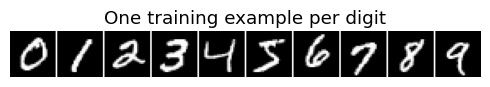

In [3]:
def show_image_grid(images, nrow=10, title=None, value_range=(0, 1)):
    """Display NCHW or NHW tensors without depending on torchvision."""
    images = images.detach().cpu()
    if images.ndim == 4:
        images = images[:, 0]
    n = len(images)
    ncol = int(np.ceil(n / nrow))
    canvas = torch.ones(ncol * 28 + (ncol - 1), nrow * 28 + (nrow - 1))
    for index, image in enumerate(images):
        row, column = divmod(index, nrow)
        top, left = row * 29, column * 29
        canvas[top : top + 28, left : left + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


# One example per class.
example_indices = [int(torch.where(y_train == digit)[0][0]) for digit in range(10)]
show_image_grid(
    x_train[example_indices], nrow=10, title="One training example per digit"
)

## 3. Image VAE architecture

The probabilistic model is unchanged:

$$p(z)=\mathcal N(0,I),\qquad
q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))).$$

What changes is the neural architecture:

- the **encoder** uses strided convolutions to map $28\times28$ images to a compact representation;
- two linear heads produce posterior mean and log variance;
- the **decoder** uses a linear layer and transposed convolutions to produce 784 Bernoulli logits.

The latent space has 16 dimensions. This is too large to plot directly but substantially smaller than the 784-dimensional observation space.

In [4]:
LATENT_DIM = 16


class ConvVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),  # 28 -> 14
            nn.SiLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 14 -> 7
            nn.SiLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.SiLU(),
        )
        self.to_mu = nn.Linear(256, latent_dim)
        self.to_logvar = nn.Linear(256, latent_dim)
        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.SiLU(), nn.Linear(256, 64 * 7 * 7), nn.SiLU()
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # 7 -> 14
            nn.SiLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),  # 14 -> 28
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h).clamp(-12, 12)

    @staticmethod
    def reparameterize(mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        h = self.decoder_input(z).reshape(-1, 64, 7, 7)
        return self.decoder(h)  # Bernoulli logits

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


model = ConvVAE(LATENT_DIM).to(DEVICE)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): SiLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): SiLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=256, bias=True)
    (6): SiLU()
  )
  (to_mu): Linear(in_features=256, out_features=16, bias=True)
  (to_logvar): Linear(in_features=256, out_features=16, bias=True)
  (decoder_input): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=3136, bias=True)
    (3): SiLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): SiLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
)
Trainable parameters: 1,688,289


## 4. ELBO for binary images

We can treat each normalized pixel as the target of an independent Bernoulli likelihood:

$$p_\theta(x\mid z)=\prod_{j=1}^{784}\operatorname{Bernoulli}(x_j;\sigma(f_\theta(z)_j)).$$

The negative reconstruction log likelihood is binary cross entropy. The negative ELBO is

$$-\operatorname{ELBO}(x)=
\underbrace{-\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]}_{\text{pixel BCE}}
+\beta\underbrace{D_{KL}(q_\phi(z\mid x)\|p(z))}_{\text{latent regularization}}.$$

We sum over pixels and latent dimensions, then average over the batch. A short KL warm-up reduces early posterior collapse. At the end we reach $\beta=1$, giving the standard VAE objective.

Strictly speaking, grayscale intensities are not binary observations. This Bernoulli decoder is a simple convenient choice commonly used for MNIST.

In [5]:
def vae_loss(images, reconstruction_logits, mu, logvar, beta=1.0):
    reconstruction_nll = (
        F.binary_cross_entropy_with_logits(
            reconstruction_logits, images, reduction="none"
        )
        .flatten(1)
        .sum(1)
    )
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1)
    return (reconstruction_nll + beta * kl).mean(), reconstruction_nll.mean(), kl.mean()


example = x_train[:16].to(DEVICE)
logits, mu, logvar = model(example)
loss, reconstruction_term, kl_term = vae_loss(example, logits, mu, logvar)
loss.backward()
assert logits.shape == example.shape
assert mu.shape == logvar.shape == (16, LATENT_DIM)
assert all(parameter.grad is not None for parameter in model.parameters())
model.zero_grad(set_to_none=True)
print(f"Sanity check passed | loss: {loss.item():.1f} nats/image")

Sanity check passed | loss: 481.7 nats/image


## 5. Train

The reconstruction term is measured over 784 pixels, whereas KL is measured over 16 latent dimensions. Their magnitudes and trends are more informative when plotted separately.

In [6]:
EPOCHS = 15 if RUN_MODE == "full" else 1
WARMUP_EPOCHS = 5
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = {"loss": [], "reconstruction": [], "kl": [], "beta": []}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    beta = min(1.0, epoch / WARMUP_EPOCHS)
    totals = np.zeros(3)
    for images, _ in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits, mu, logvar = model(images)
        values = vae_loss(images, logits, mu, logvar, beta)
        values[0].backward()
        optimizer.step()
        totals += np.array([value.item() for value in values]) * len(images)
    averages = totals / len(train_loader.dataset)
    for key, value in zip(["loss", "reconstruction", "kl"], averages):
        history[key].append(value)
    history["beta"].append(beta)
    print(
        f"epoch {epoch:2d}/{EPOCHS} | beta {beta:.2f} | loss {averages[0]:7.2f} | "
        f"recon {averages[1]:7.2f} | KL {averages[2]:6.2f}"
    )
print(f"Training time: {time.time() - start:.1f} s")

epoch  1/15 | beta 0.20 | loss  169.97 | recon  164.55 | KL  27.09
epoch  2/15 | beta 0.40 | loss  100.07 | recon   87.36 | KL  31.76
epoch  3/15 | beta 0.60 | loss   97.26 | recon   80.06 | KL  28.67
epoch  4/15 | beta 0.80 | loss   99.75 | recon   78.70 | KL  26.32
epoch  5/15 | beta 1.00 | loss  103.25 | recon   78.92 | KL  24.33
epoch  6/15 | beta 1.00 | loss  101.90 | recon   77.64 | KL  24.26
epoch  7/15 | beta 1.00 | loss  100.94 | recon   76.69 | KL  24.25
epoch  8/15 | beta 1.00 | loss  100.16 | recon   75.96 | KL  24.21
epoch  9/15 | beta 1.00 | loss   99.49 | recon   75.32 | KL  24.16
epoch 10/15 | beta 1.00 | loss   98.89 | recon   74.78 | KL  24.11
epoch 11/15 | beta 1.00 | loss   98.48 | recon   74.42 | KL  24.06
epoch 12/15 | beta 1.00 | loss   97.97 | recon   73.98 | KL  24.00
epoch 13/15 | beta 1.00 | loss   97.60 | recon   73.66 | KL  23.93
epoch 14/15 | beta 1.00 | loss   97.22 | recon   73.31 | KL  23.90
epoch 15/15 | beta 1.00 | loss   96.89 | recon   73.00 | KL  2

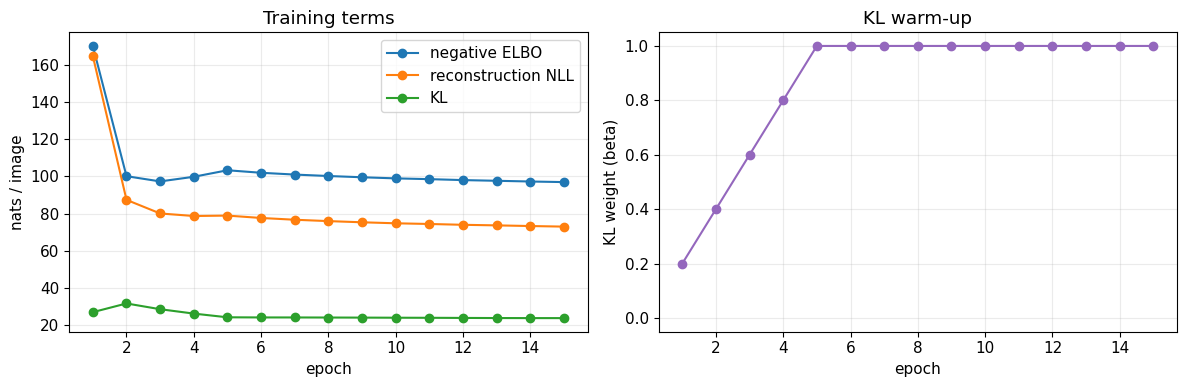

In [7]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["loss"], marker="o", label="negative ELBO")
axes[0].plot(epochs, history["reconstruction"], marker="o", label="reconstruction NLL")
axes[0].plot(epochs, history["kl"], marker="o", label="KL")
axes[0].set(xlabel="epoch", ylabel="nats / image", title="Training terms")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].plot(epochs, history["beta"], marker="o", color="tab:purple")
axes[1].set(
    xlabel="epoch", ylabel="KL weight (beta)", ylim=(-0.05, 1.05), title="KL warm-up"
)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Held-out ELBO and reconstructions

Reconstructions use the posterior mean $\mu_\phi(x)$, making the comparison deterministic. The decoder outputs Bernoulli probabilities, displayed as grayscale intensities.

Good reconstructions demonstrate information flow through $z$, but they do **not** by themselves prove that prior samples will be good. Generation additionally requires the encoded latent distribution to align with the prior.

Test negative ELBO: 97.15 nats/image
  reconstruction: 73.75 | KL: 23.40


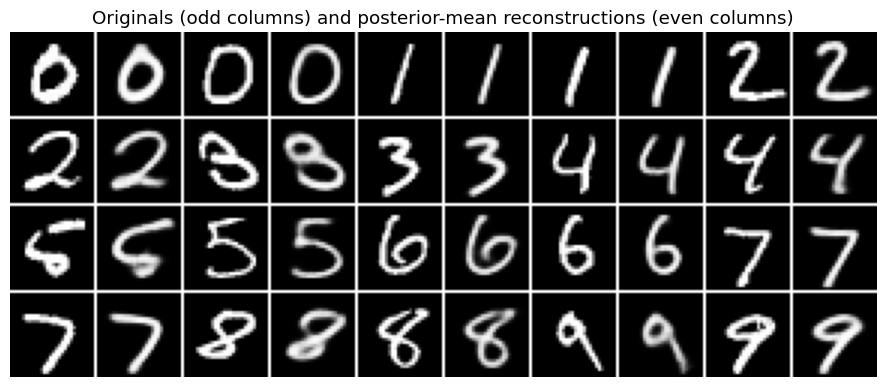

In [8]:
model.eval()
test_totals = np.zeros(3)
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        logits, mu, logvar = model(images)
        values = vae_loss(images, logits, mu, logvar, beta=1.0)
        test_totals += np.array([value.item() for value in values]) * len(images)
test_averages = test_totals / len(x_test)
print(f"Test negative ELBO: {test_averages[0]:.2f} nats/image")
print(f"  reconstruction: {test_averages[1]:.2f} | KL: {test_averages[2]:.2f}")

# Choose two examples per class for a balanced display.
indices = torch.cat([torch.where(y_test == digit)[0][:2] for digit in range(10)])
originals = x_test[indices].to(DEVICE)
with torch.no_grad():
    posterior_mu, _ = model.encode(originals)
    reconstructions = model.decode(posterior_mu).sigmoid()
paired = torch.stack([originals.cpu(), reconstructions.cpu()], dim=1).reshape(
    -1, 1, 28, 28
)
show_image_grid(
    paired,
    nrow=10,
    title="Originals (odd columns) and posterior-mean reconstructions (even columns)",
)

## 7. Generate new digits from the prior

Generation does not use the encoder:

$$z\sim\mathcal N(0,I),\qquad
p=\sigma(f_\theta(z)).$$

The displayed images are decoder probabilities. A literal sample from the Bernoulli likelihood would additionally draw every pixel independently. Probability images are less noisy and easier to inspect.

### Predict before running

> **Commit to a prediction:** compared with the reconstructions above, will samples from $z\sim\mathcal N(0,I)$ be sharper, blurrier, or similarly coherent? Justify using the difference between encoding a real image and drawing from the prior.

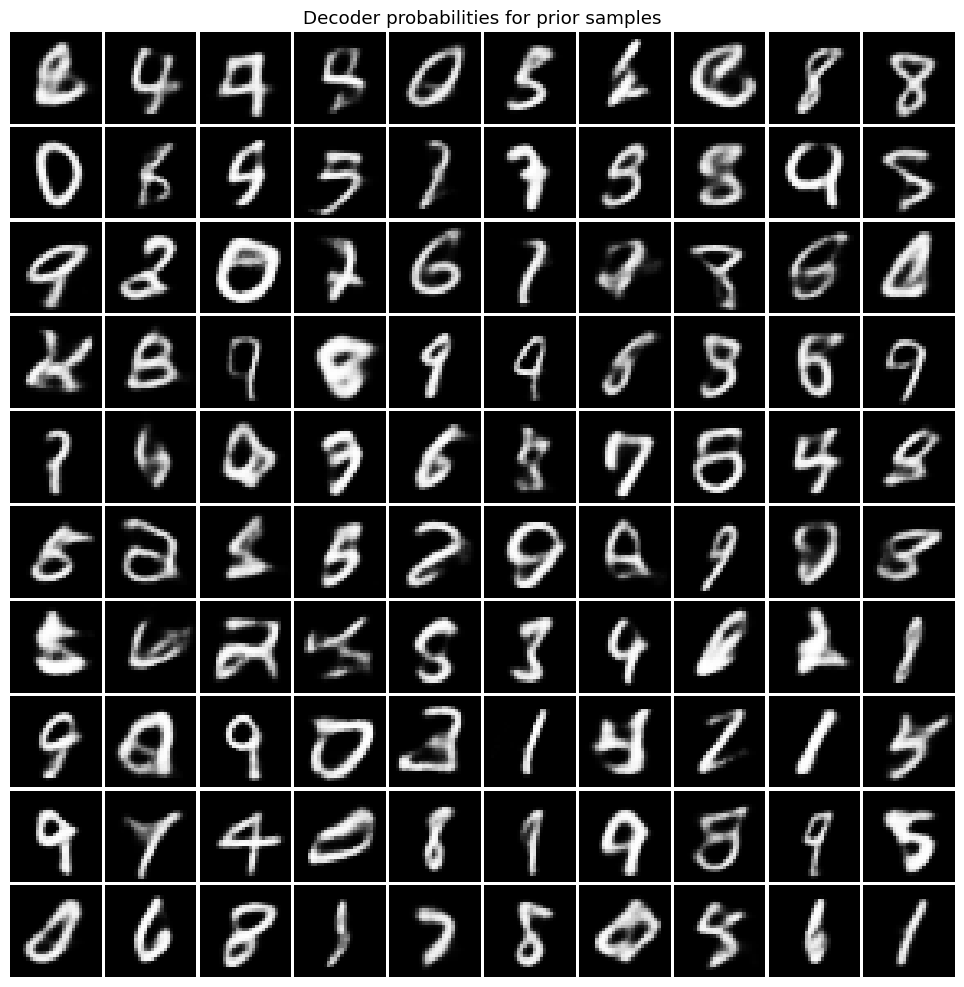

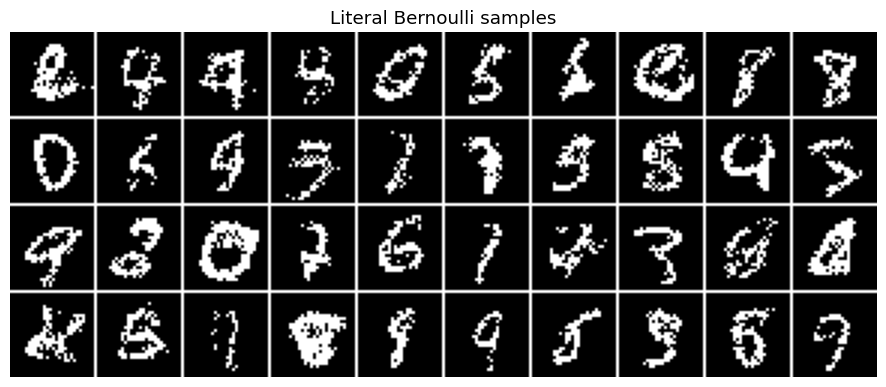

In [9]:
with torch.no_grad():
    prior_z = torch.randn(100, LATENT_DIM, device=DEVICE)
    generated_probabilities = model.decode(prior_z).sigmoid().cpu()
    generated_binary = torch.bernoulli(generated_probabilities)

show_image_grid(
    generated_probabilities, nrow=10, title="Decoder probabilities for prior samples"
)
show_image_grid(generated_binary[:40], nrow=10, title="Literal Bernoulli samples")

> **Expected observation / interpretation.** Prior samples are typically less consistently digit-like than reconstructions because they test both decoder quality and alignment of the aggregated posterior with $\mathcal N(0,I)$. Decoder probabilities look smoother than literal Bernoulli draws.

## 8. Latent interpolation

The continous latent representation allows us to encode two test images and linearly interpolate between their posterior means. Smooth transitions indicate that nearby latent points decode to related images.

Linear interpolation is easy to visualize, although straight lines in Euclidean coordinates are not necessarily geodesics of the learned data manifold.

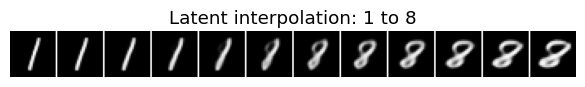

In [10]:
digit_a, digit_b = 1, 8
index_a = int(torch.where(y_test == digit_a)[0][0])
index_b = int(torch.where(y_test == digit_b)[0][0])
endpoints = x_test[[index_a, index_b]].to(DEVICE)
with torch.no_grad():
    endpoint_mu, _ = model.encode(endpoints)
    weights = torch.linspace(0, 1, 12, device=DEVICE).unsqueeze(1)
    interpolated_z = (1 - weights) * endpoint_mu[0] + weights * endpoint_mu[1]
    interpolation = model.decode(interpolated_z).sigmoid().cpu()
show_image_grid(
    interpolation, nrow=12, title=f"Latent interpolation: {digit_a} to {digit_b}"
)

## 9. Aggregated posterior in two dimensions

The latent space has 16 dimensions, so we project posterior means onto their two leading principal components. We fit a PCA here with `torch.linalg.svd`. Labels are used only to color the plot.

This projection can reveal class organization, but overlap in 2D does not imply overlap in the full latent space. Neither does a missing clustering in this 2D projection imply insufficient clustering in latent space.

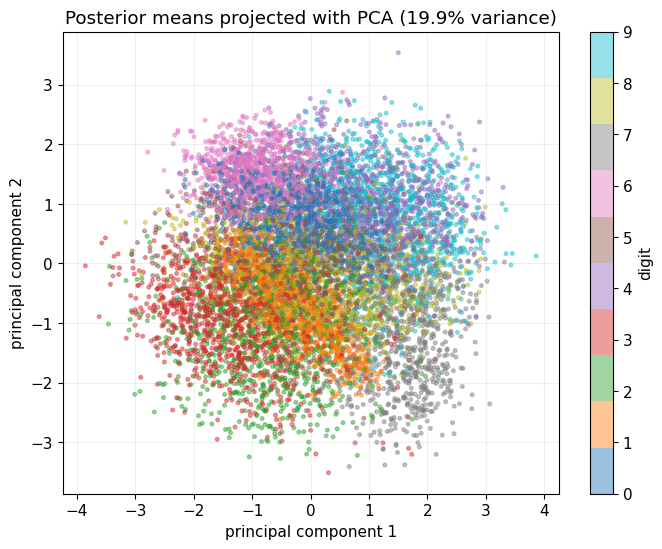

In [11]:
model.eval()
latent_means, latent_logvars, latent_labels = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        mu, logvar = model.encode(images.to(DEVICE, non_blocking=True))
        latent_means.append(mu.cpu())
        latent_logvars.append(logvar.cpu())
        latent_labels.append(labels)
latent_means = torch.cat(latent_means)
latent_logvars = torch.cat(latent_logvars)
latent_labels = torch.cat(latent_labels)

centered = latent_means - latent_means.mean(0)
_, singular_values, directions = torch.linalg.svd(centered, full_matrices=False)
projection = centered @ directions[:2].T
explained = singular_values.square() / singular_values.square().sum()

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    projection[:, 0], projection[:, 1], c=latent_labels, cmap="tab10", s=7, alpha=0.45
)
ax.set(
    title=f"Posterior means projected with PCA ({100*explained[:2].sum():.1f}% variance)",
    xlabel="principal component 1",
    ylabel="principal component 2",
)
ax.grid(alpha=0.2)
fig.colorbar(scatter, ax=ax, ticks=range(10), label="digit")
plt.show()

## 10. Which latent dimensions are active?

For each dimension, we can examine:

- the variance of posterior means across data;
- the mean posterior standard deviation;
- the mean per-dimension KL contribution.

A dimension with nearly zero mean variation and nearly unit posterior standard deviation carries little information about $x$. This is sometimes called an **inactive unit** and is related to **posterior collapse**.

### Predict before running

> **Commit to a prediction:** will all 16 latent coordinates carry comparable information? Predict the qualitative shape of the per-dimension KL plot and justify what would make a dimension “inactive.”

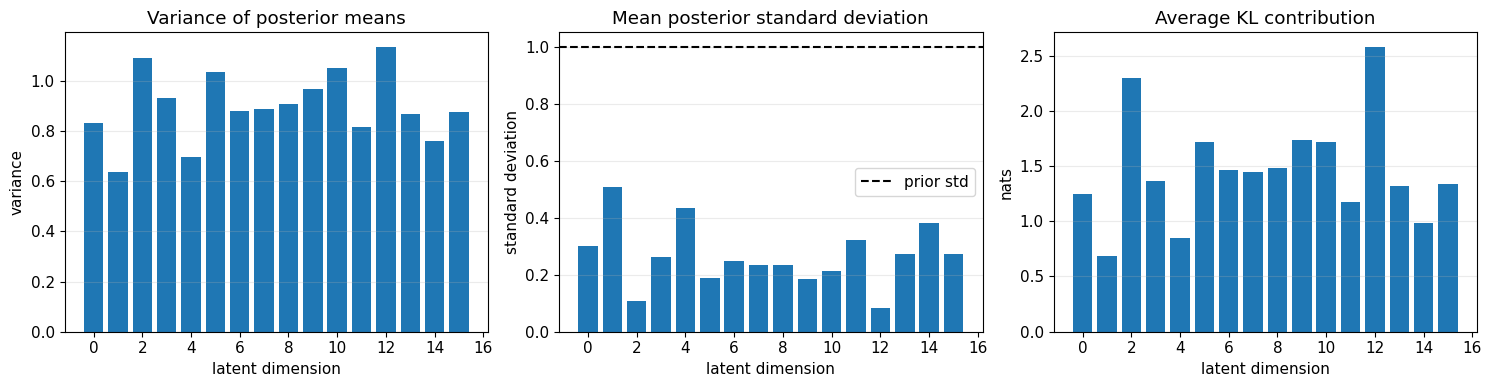

Dimensions with KL > 0.1 nat: 16/16


In [12]:
mean_variance = latent_means.var(0)
posterior_std = torch.exp(0.5 * latent_logvars).mean(0)
kl_per_dimension = -0.5 * (
    1 + latent_logvars - latent_means.square() - latent_logvars.exp()
).mean(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
dimensions = np.arange(LATENT_DIM)
axes[0].bar(dimensions, mean_variance.numpy())
axes[0].set(
    title="Variance of posterior means", xlabel="latent dimension", ylabel="variance"
)
axes[1].bar(dimensions, posterior_std.numpy())
axes[1].axhline(1, color=PLOT_GUIDE_COLOR, linestyle="--", label="prior std")
axes[1].set(
    title="Mean posterior standard deviation",
    xlabel="latent dimension",
    ylabel="standard deviation",
)
axes[1].legend()
axes[2].bar(dimensions, kl_per_dimension.numpy())
axes[2].set(title="Average KL contribution", xlabel="latent dimension", ylabel="nats")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print(
    f"Dimensions with KL > 0.1 nat: {(kl_per_dimension > .1).sum().item()}/{LATENT_DIM}"
)

> **Expected observation / interpretation.** Information use is usually uneven. Several coordinates can have appreciable KL/mean variation while others remain near the unit-Gaussian prior. Near-zero per-dimension KL is evidence of an inactive unit, not a proof that the whole VAE has collapsed.

## 11. Latent traversals

To interpret individual dimensions, we can start from the average posterior mean and vary one coordinate while fixing all others. We traverse the four dimensions with the largest average KL contribution.

A coordinate may control digit identity, stroke thickness, slant, loop shape, or several entangled properties. Standard VAEs do not guarantee disentanglement of coordinates tho.

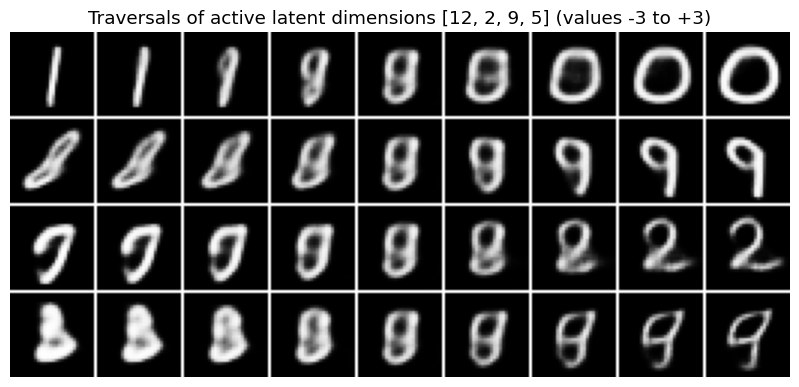

In [13]:
most_active = torch.topk(kl_per_dimension, k=4).indices
traversal_values = torch.linspace(-3, 3, 9, device=DEVICE)
base = latent_means.mean(0).to(DEVICE)
rows = []
with torch.no_grad():
    for dimension in most_active:
        z = base.repeat(len(traversal_values), 1)
        z[:, dimension] = traversal_values
        rows.append(model.decode(z).sigmoid().cpu())
traversals = torch.cat(rows)
show_image_grid(
    traversals,
    nrow=9,
    title=f"Traversals of active latent dimensions {most_active.tolist()} (values -3 to +3)",
)

## 12. Reconstruction uncertainty

The encoder defines a distribution, not a single code. Let's repeatedly sample $z\sim q_\phi(z\mid x)$ for the same image and decode it. Variation across outputs reflects posterior uncertainty combined with decoder sensitivity.

The posterior-mean reconstruction is shown first, followed by stochastic reconstructions.

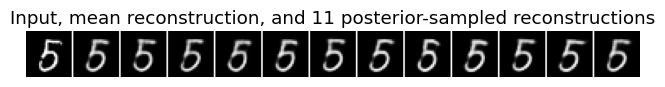

In [17]:
uncertain_index = int(torch.where(y_test == 5)[0][3])
source = x_test[uncertain_index : uncertain_index + 1].to(DEVICE)
with torch.no_grad():
    source_mu, source_logvar = model.encode(source)
    sampled_z = source_mu + torch.exp(0.5 * source_logvar) * torch.randn(
        11, LATENT_DIM, device=DEVICE
    )
    stochastic_reconstructions = model.decode(sampled_z).sigmoid().cpu()
    mean_reconstruction = model.decode(source_mu).sigmoid().cpu()
comparison = torch.cat([source.cpu(), mean_reconstruction, stochastic_reconstructions])
show_image_grid(
    comparison,
    nrow=13,
    title="Input, mean reconstruction, and 11 posterior-sampled reconstructions",
)

## 13. Takeaways and homework experiments

### Takeaways
- The probabilistic VAE formulation is unchanged when moving from 2D points to images.
- Convolutions add an image-appropriate inductive bias without changing the ELBO.
- A Bernoulli decoder turns reconstruction into pixelwise binary cross entropy.
- Reconstructions test encoding and decoding; prior samples additionally test prior alignment.
- Interpolations and traversals probe latent geometry.
- Per-dimension KL exposes inactive latent units and posterior collapse.

### Mini-experiment 1 — Latent capacity
- **Hypothesis:** Increasing `LATENT_DIM` improves reconstruction only until optimization or regularization leaves extra units inactive.
- **Metric/plot:** Plot held-out reconstruction nats, prior-sample grids, and active-dimension count for 2, 8, 32, and 64 dimensions.
- **Controls:** Keep data split, seed, architecture outside the bottleneck, epochs, and beta schedule fixed.
- **Interpretation:** Separate capacity gains from prior mismatch. More coordinates are not useful if their KL remains near zero. 

### Mini-experiment 2 — Linear versus spherical interpolation
- **Hypothesis:** Spherical interpolation stays closer to a typical Gaussian radius and may yield more plausible intermediate digits than a straight line.
- **Metric/plot:** Show aligned interpolation grids and plot latent norm along each path.
- **Controls:** Use the same endpoint images, posterior means, decoder, and interpolation weights.
- **Interpretation:** Relate visual continuity to where each path travels under the prior.

### Extensions
- Remove KL warm-up and inspect active dimensions.
- Set a final $\beta>1$ for a $\beta$-VAE. Compare disentanglement and sharpness.
- Set $\beta<1$. Reconstructions often improve while prior samples degrade.
- Binarize MNIST dynamically during training instead of using grayscale targets.
- Replace the Bernoulli likelihood with a continuous likelihood.
- Add labels to obtain a conditional VAE.

## Exit ticket

1. Which parts of the VAE objective are unchanged from 2D data, and what do convolutions change?
<details><summary>Self-check</summary>The ELBO, prior, reparameterization, and KL are unchanged. Convolutions add an image-specific encoder/decoder inductive bias.</details>

2. Why can reconstructions look good while prior samples remain weak?
<details><summary>Self-check</summary>Reconstructions use latents inferred from real images. Prior samples also require the aggregated posterior to align with the prior.</details>

3. What evidence marks a latent coordinate as inactive?
<details><summary>Self-check</summary>Near-zero per-dimension KL, little variation in posterior means, and posterior scale near one indicate little information use.</details>

## References and further reading

- [Kingma & Welling, “Auto-Encoding Variational Bayes” (2014)](https://arxiv.org/abs/1312.6114): Foundational derivation of the reparameterized variational objective used here.
- [Official PyTorch VAE example](https://github.com/pytorch/examples/tree/main/vae): A compact, accessible implementation for comparing engineering choices.